# Franklin County probate sample: first look

Three charts and a scale estimate from the first real run of the scraper (estates opened 3 and 4 March 2025, Franklin County Probate Court, Ohio).

Franklin County stands in for the real target, North Carolina (Union County first), whose court records sit behind a bot check. The fields and the pipeline carry over; the source pages will not.

**Data.** The notebook reads the masked CSV that `python -m scraper.run_sample` writes to `data/sample/franklin_sample_masked.csv`. That file stays on your machine and is not in the repo. Names are already reduced to initials and salted ids by the scraper, and nothing below prints a row; every figure is a count, a median or a dot with no label.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

# Works whether the notebook is started from the repo root or from notebooks/.
CSV = next(p for p in (Path("data/sample/franklin_sample_masked.csv"),
                       Path("../data/sample/franklin_sample_masked.csv")) if p.exists())

raw = pd.read_csv(CSV, dtype={"case_number": str})
# The court's "Next Cases" page repeats the previous page's last case; runs made
# before the paging fix can hold that case twice.
df = raw.drop_duplicates("case_number").copy()
print(f"{len(raw)} rows read, {len(df)} distinct estates")

30 rows read, 29 distinct estates


In [2]:
# Chart style: thin marks, quiet axes, fixed colours (blue first, orange second).
BLUE, ORANGE = "#257de0", "#f47230"
INK, INK_2, GRID = "#191919", "#666666", "#e6e6e6"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "figure.facecolor": "white",
    "axes.facecolor": "white", "axes.edgecolor": GRID, "axes.labelcolor": INK_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "x", "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_2, "ytick.color": INK, "ytick.left": False,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 22, "text.color": INK,
})

TIERS = {"full": "Full administration", "release": "Release from administration",
         "summary": "Summary release", "other": "Real estate only"}
df["tier"] = pd.Categorical(df["admin_tier"].map(TIERS).fillna("Real estate only"),
                            categories=list(TIERS.values()), ordered=True)
df["will"] = df["has_will"].astype(str).str.lower().map({"true": True, "false": False})

def subtitle(ax, text):
    ax.text(0, 1.02, text, transform=ax.transAxes, color=INK_2, fontsize=9, va="bottom")

df.groupby("tier", observed=False).agg(
    estates=("case_number", "size"), with_will=("will", "sum"),
    closed=("days_to_close", "count"), median_days_to_close=("days_to_close", "median"),
    inventories_filed=("inventory_value", "count"))

,estates,with_will,closed,median_days_to_close,inventories_filed
tier,,,,,
Full administration,19,13,16,281.5,19
Release from administration,6,4,6,20.5,0
Summary release,3,2,3,1.0,0
Real estate only,1,0,1,238.0,0


## 1. Days from opening to closing, by administration tier

Release and summary cases are Ohio's small-estate routes and close within weeks; full administrations take most of a year. Estates still open are counted in the row label but have no dot.

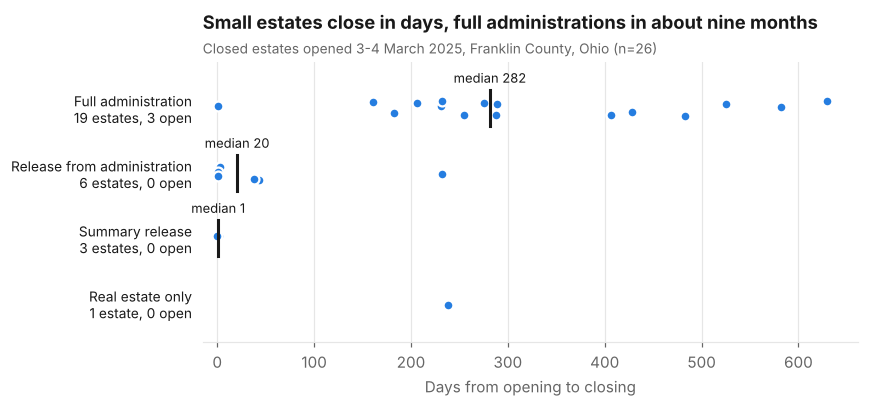

In [3]:
tiers = [t for t in TIERS.values() if (df["tier"] == t).any()]
fig, ax = plt.subplots(figsize=(8, 3.8))
rng = np.random.default_rng(0)  # fixed jitter so reruns look the same
for i, t in enumerate(tiers):
    rows = df[df["tier"] == t]
    days = rows["days_to_close"].dropna()
    y = len(tiers) - 1 - i
    ax.scatter(days, y + rng.uniform(-0.12, 0.12, len(days)), s=42, color=BLUE,
               edgecolor="white", linewidth=1.5, zorder=3)
    if len(days) >= 3:  # a median of one or two dots says nothing
        med = days.median()
        ax.plot([med, med], [y - 0.28, y + 0.28], color=INK, linewidth=2, zorder=4)
        ax.text(med, y + 0.34, f"median {med:.0f}", ha="center", va="bottom", fontsize=8.5, color=INK)
labels = [f"{t}\n{(n := (df['tier'] == t).sum())} estate{'s' if n != 1 else ''}, {df.loc[df['tier'] == t, 'is_open'].astype(str).str.lower().eq('true').sum()} open"
          for t in tiers]
ax.set_yticks(range(len(tiers)))
ax.set_yticklabels(labels[::-1], fontsize=9)
ax.set_ylim(-0.6, len(tiers) - 0.3)
ax.set_xlim(-15, None)
ax.set_xlabel("Days from opening to closing")
ax.set_title("Small estates close in days, full administrations in about nine months")
subtitle(ax, f"Closed estates opened 3-4 March 2025, Franklin County, Ohio (n={df['days_to_close'].notna().sum()})")
fig.tight_layout()
plt.show()

## 2. Inventory values, full administrations

An inventory is filed only in full administrations, so this is those estates alone. The values span three orders of magnitude, hence the log scale. One estate filed an inventory of $0, which a log scale cannot show; it is counted in the note below the chart.

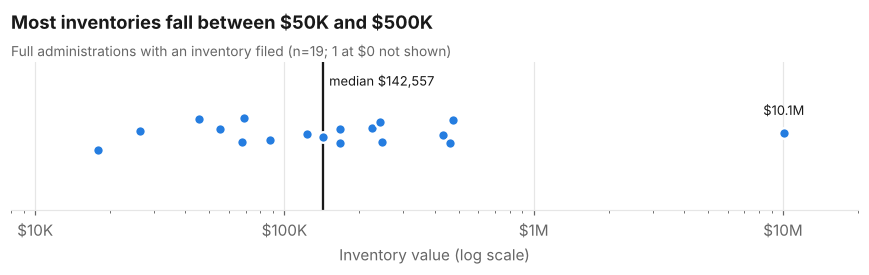

Median $142,557; without the largest estate $132,730


In [4]:
inv = df.loc[df["inventory_value"].notna(), "inventory_value"]
pos = inv[inv > 0]
fig, ax = plt.subplots(figsize=(8, 2.6))
ax.scatter(pos, rng.uniform(-0.15, 0.15, len(pos)), s=48, color=BLUE,
           edgecolor="white", linewidth=1.5, zorder=3)
med = inv.median()
ax.axvline(med, color=INK, linewidth=1.5, zorder=2)
ax.text(med * 1.06, 0.45, f"median ${med:,.0f}", ha="left", va="center", fontsize=8.5, color=INK)
top = pos.max()
ax.annotate(f"${top / 1e6:.1f}M", (top, 0), xytext=(0, 14), textcoords="offset points",
            ha="center", fontsize=8.5, color=INK)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda v, _: f"${v / 1e6:.0f}M" if v >= 1e6 else f"${v / 1e3:.0f}K"))
ax.set_xlim(8e3, 2e7)
ax.set_ylim(-0.6, 0.6)
ax.set_yticks([])
ax.set_xlabel("Inventory value (log scale)")
ax.set_title(r"Most inventories fall between \$50K and \$500K")
subtitle(ax, f"Full administrations with an inventory filed (n={len(inv)}; "
             f"{(inv == 0).sum()} at $0 not shown)")
fig.tight_layout()
plt.show()
print(f"Median ${inv.median():,.0f}; without the largest estate ${inv[inv < top].median():,.0f}")

## 3. Will or no will, within each tier

The scraper reads this from the case subtype (for example "Full Administration with Will"), so it is known for every estate.

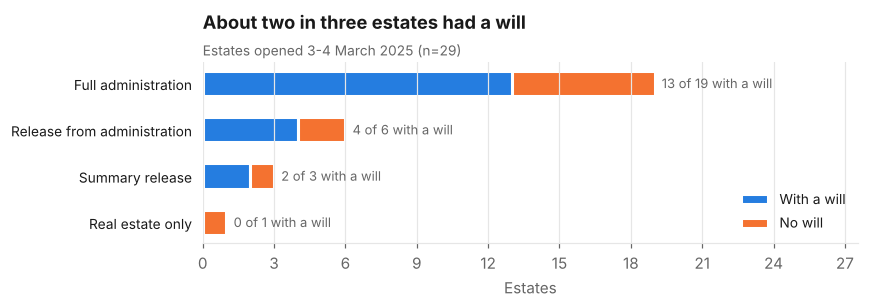

In [5]:
counts = (df.groupby("tier", observed=True)["will"].agg(with_will="sum", total="size")
          .assign(no_will=lambda t: t["total"] - t["with_will"]))
counts = counts.loc[[t for t in TIERS.values() if t in counts.index][::-1]]
fig, ax = plt.subplots(figsize=(8, 2.9))
y = np.arange(len(counts))
ax.barh(y, counts["with_will"], color=BLUE, height=0.55, edgecolor="white", linewidth=2, label="With a will")
ax.barh(y, counts["no_will"], left=counts["with_will"], color=ORANGE, height=0.55,
        edgecolor="white", linewidth=2, label="No will")
for yi, (w, n) in enumerate(zip(counts["with_will"], counts["total"])):
    ax.text(n + 0.3, yi, f"{w} of {n} with a will", va="center", fontsize=8.5, color=INK_2)
ax.set_yticks(y)
ax.set_yticklabels(counts.index, fontsize=9)
ax.set_xlim(0, counts["total"].max() * 1.45)
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
ax.set_xlabel("Estates")
ax.set_title("About two in three estates had a will")
subtitle(ax, f"Estates opened 3-4 March 2025 (n={len(df)})")
ax.legend(loc="lower right", frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

## 4. What a full year would take

A rough estimate from this run, to size the job rather than to plan it.

* **Requests per estate.** Each estate takes three page loads (detail, fiduciaries, docket). The run made 89 requests: 87 for the 29 estates and 2 for the date index. The repeated case was served from the local cache, so it cost nothing.
* **Estates per year.** 21 estates opened on Monday 3 March 2025, the one full day in the sample (the run stopped partway through 4 March at its 30-case limit). One day is a thin basis; at about 250 court days a year that is roughly 5,000 estates.
* **Time.** The scraper waits 3 seconds between requests and the court's search is offline from 10 PM to 2 AM Eastern, so a year of Franklin estates is roughly 13 hours of running, which fits in one day around that window. An index-only pass (case numbers, types and dates, no case pages) takes minutes.

**The real target is North Carolina.** NC eCourts sits behind a bot check, so this scraper cannot be pointed at Union County as it stands. A bulk records request to the NC Administrative Office of the Courts is the likelier route there, and the field list in the README is what such a request would ask for.

In [6]:
REQUESTS_THIS_RUN = 89      # from the run's log on 26 Nov 2026
PAGES_PER_ESTATE = 3         # detail, fiduciaries, docket
ESTATES_ON_FULL_DAY = int((pd.to_datetime(df["open_date"]) == "2025-03-03").sum())
COURT_DAYS = 250
SECONDS_PER_REQUEST = 3      # scraper.config rate limit
INDEX_PAGES_PER_DAY = 1      # 40 cases a page, all case types mixed; a busy day may take 2

estates_year = ESTATES_ON_FULL_DAY * COURT_DAYS
requests_year = estates_year * PAGES_PER_ESTATE + COURT_DAYS * INDEX_PAGES_PER_DAY
hours = requests_year * SECONDS_PER_REQUEST / 3600
print(f"This run: {REQUESTS_THIS_RUN} requests for {len(df)} estates "
      f"({REQUESTS_THIS_RUN / len(df):.1f} per estate)")
print(f"A year:   about {estates_year:,} estates, {requests_year:,} requests, "
      f"{hours:.0f} hours at {SECONDS_PER_REQUEST} s each "
      f"(the court allows about 20 hours a day)")
print(f"Index only: {COURT_DAYS * INDEX_PAGES_PER_DAY} pages, "
      f"about {COURT_DAYS * INDEX_PAGES_PER_DAY * SECONDS_PER_REQUEST / 60:.0f} minutes")

This run: 89 requests for 29 estates (3.1 per estate)
A year:   about 5,250 estates, 16,000 requests, 13 hours at 3 s each (the court allows about 20 hours a day)
Index only: 250 pages, about 12 minutes
